# Math documents / CC：math SFT 后的文档检索验证

**Run：** `math-web-probe-qwen25-1p5b-n4096-b64-s64-seed42`  
**结果时间（UTC）：** 2026-10-23T09:58:32.795444+00:00

在 4,096 条多题型 MATH 问答上训练 64 步，比较原始 ref 与预先固定的 **step 64** 模型。
候选池包含 1,000 篇 OpenWebMath 注入文档和 9,000 篇未标注 CC 背景网页。
两项指标并列考察，不设主次：loss 下降量 ROC-AUC **0.3046**（95% CI 0.2856–0.3226）；相对下降比例 ROC-AUC **0.2137**（95% CI 0.1962–0.2312）。

本页验证问答任务的学习信号能否迁移到文档检索；没有进行选中文档后的再次训练。
所有表格和图已执行保存，重跑只需要本目录快照和 CPU。

## 1. 数据与评价约定

两种来源都限定在 `CC-MAIN-2023-06`，在固定源分片内随机抽样。
OpenWebMath 和 FineWeb 的上游提取/质量筛选不同；这一来源差异仍然存在。
**标签表示是否来自注入的 OpenWebMath 集合，不是人工核验的数学内容标签。**
CC 背景可能含数学内容，因此以下 precision/recall/enrichment 都是注入来源的检索指标。

网页使用原始正文，不加聊天模板。每个 token（每篇第一个除外）评分一次，窗口最多 2,048 tokens。
整篇 NLL = 所有窗口 NLL 总和 / 实际评分 token 总数；再计算下降量与相对下降比例。
分数越大越倾向注入来源，方向固定。raw-loss 基线同时展示，未按观察到的 AUC 翻转分数。
置信区间为按来源分层、按重复文档组重采样的 2,000 次 bootstrap。

In [1]:
import hashlib,json,math,os
import tempfile
from pathlib import Path
if 'MPLCONFIGDIR' not in os.environ:
    scratch=Path('/dev/shm/data-picking-runtime') if Path('/dev/shm').is_dir() else Path(tempfile.gettempdir())/'data-picking-runtime'
    os.environ['MPLCONFIGDIR']=str(scratch/'matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from sklearn.metrics import roc_auc_score,average_precision_score,roc_curve
%matplotlib inline
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',80)

In [2]:
DIRECTORY = '2026-10-23_095832Z_math-web-probe-qwen25-1p5b-n4096-b64-s64-seed42'

HERE=next((p for p in [Path.cwd(),Path.cwd()/'experiments-analysis'/DIRECTORY] if (p/'snapshot').is_dir() and (p/'manifest.json').is_file()),None)
if HERE is None:raise FileNotFoundError('请使用当前实验目录或仓库根目录。')
SNAP=HERE/'snapshot';manifest=json.loads((HERE/'manifest.json').read_text())
for name,info in manifest['files'].items():
    data=(SNAP/name).read_bytes()
    assert len(data)==info['bytes'] and hashlib.sha256(data).hexdigest()==info['sha256'],name
def load(name):return json.loads((SNAP/name).read_text())
metrics=load('metrics.json');effective=load('effective_config.json');dataset=load('dataset_summary.json')
plan=load('evaluation_plan.json');completed=load('training_complete.json')
df=pd.read_parquet(SNAP/'per_document.parquet')
windows=pd.read_parquet(SNAP/'per_window.parquet')
target=pd.read_parquet(SNAP/'target_validation.parquet')
training=pd.read_json(SNAP/'train.jsonl',lines=True)
matched=df.set_index('id').loc[load('length_matched_ids.json')].reset_index()
assert df['id'].is_unique and df.groupby('source').size().to_dict()=={'background':9000,'math':1000}
assert len(windows)==metrics['windows'] and int(df['scored_tokens'].sum())==metrics['scored_tokens']
totals=windows.groupby('document_id')[['ref_sum_nll','sft_sum_nll','scored_tokens']].sum()
aligned=df.set_index('id').loc[totals.index]
for prefix in ['ref','sft']:
    np.testing.assert_allclose(totals[f'{prefix}_sum_nll']/totals['scored_tokens'],aligned[f'{prefix}_mean_nll'],rtol=0,atol=1e-12)
assert completed['global_step']==64 and training['step'].tolist()==list(range(1,65))
assert training['response_tokens'].sum()==completed['seen_response_tokens']==dataset['target']['splits']['train']['response_tokens']
keys=['delta_loss','relative_gain','neg_ref_loss','neg_sft_loss']
names={'math':'Injected OpenWebMath','background':'Unlabeled CC background'}
colors={'math':'#1674B8','background':'#DF7931'}
labels={'delta_loss':'loss 下降量','relative_gain':'相对下降比例','neg_ref_loss':'ref loss，低值优先','neg_sft_loss':'SFT loss，低值优先'}
def interval(v):return f'[{v[0]:.4f}, {v[1]:.4f}]'
print(f'快照及文档 NLL 聚合核对通过：{len(df):,} 篇网页，{len(windows):,} 个窗口，{metrics["scored_tokens"]:,} 个评分 token。')

快照及文档 NLL 聚合核对通过：10,000 篇网页，11,688 个窗口，9,188,836 个评分 token。


## 2. 固定训练设置与留出验证集

,设置,值
0,模型,Qwen/Qwen2.5-1.5B-Instruct
1,模型 revision,989aa7980e4cf806f80c7fef2b1adb7bc71aa306
2,训练 / 验证样本,4096 / 512
3,有效 batch / micro batch / 累积,64 / 2 / 32
4,训练步数 / 学习率,64 / 2e-05
5,checkpoint,"16, 32, 48, 64；最终结果固定为 64"
6,训练 / 评分精度,float32 master + bf16 autocast / full float32；SDPA math
7,optimizer 保存 / 自动恢复,True / True


,train,validation
counting_and_probability,542,68
prealgebra,782,96
algebra,907,114
number_theory,279,36
intermediate_algebra,922,115
geometry,241,30
precalculus,423,53


,step,optimizer_steps,scheduler_step,saved_rng_keys,saved_orders,seen_response_tokens,state_sha256
16,16,[16],16,"[cuda, numpy, python, torch]",1,208088,fc534a9a378f1b2334257f82e9fe98940734d211a957947d092788c173b5856e
32,32,[32],32,"[cuda, numpy, python, torch]",1,414576,16e63b4022534bb3e225d14c2dcb81df64c8738c0388557ee9eb5cfbe25924b4
48,48,[48],48,"[cuda, numpy, python, torch]",1,615954,9e5988735a9de8bee9e68fdbac6c30683092cab0aedf0690f6da61dca9986daf
64,64,[64],64,"[cuda, numpy, python, torch]",1,830862,ef43521b16315fa0d124b51a8879839efffc88ae789e654e83a5ec989292a28b


,model,shard,unit,repeat max,padding max,window padding max,tolerance
0,reference_web,0,whole_document_mean_nll,7.582007e-07,0.000001,0.000001,0.00002
1,reference_web,1,whole_document_mean_nll,5.638352e-07,0.000001,0.000028,0.00002
2,sft_web,0,whole_document_mean_nll,4.438920e-07,0.000001,0.000003,0.00002
3,sft_web,1,whole_document_mean_nll,5.695349e-07,0.000002,0.000008,0.00002


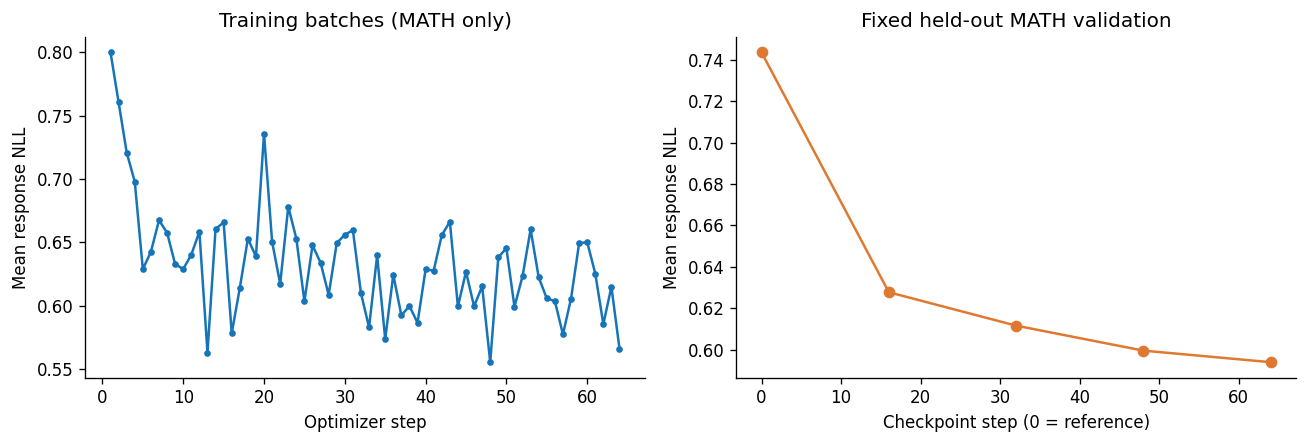

,checkpoint_step,examples,mean_nll,mean_drop_from_ref,fraction_improved
0,0,512,0.74350,0.00000,0.00000
1,16,512,0.62777,0.11573,0.91602
2,32,512,0.61166,0.13184,0.94336
3,48,512,0.59960,0.14390,0.95898
4,64,512,0.59402,0.14948,0.97656


In [3]:
cfg=effective['config']
display(pd.DataFrame([
    ('模型',cfg['model']['name']),('模型 revision',cfg['model']['revision']),
    ('训练 / 验证样本',f"{effective['actual_train_size']} / {dataset['target']['splits']['validation']['examples']}"),
    ('有效 batch / micro batch / 累积',f"{cfg['training']['effective_batch_size']} / {cfg['training']['micro_batch_size']} / {effective['gradient_accumulation_steps']}"),
    ('训练步数 / 学习率',f"{completed['global_step']} / {cfg['training']['learning_rate']}"),
    ('checkpoint', '16, 32, 48, 64；最终结果固定为 64'),
    ('训练 / 评分精度','float32 master + bf16 autocast / full float32；SDPA math'),
    ('optimizer 保存 / 自动恢复',f"{effective['save_optimizer']} / {effective['auto_resume']}"),
],columns=['设置','值']))
display(pd.DataFrame(dataset['target']['splits']['train']['subjects'],index=['train']).T.join(
    pd.Series(dataset['target']['splits']['validation']['subjects'],name='validation')))
display(pd.DataFrame(load('checkpoint_state_checks.json')).T)
checks=[]
for model in ['reference_web','sft_web']:
    for value in metrics['score_sanity'][model]:
        checks.append({'model':model,'shard':value['shard'],'unit':value.get('unit','window_mean_nll'),
                       'repeat max':value['repeat_max_nll_difference'],'padding max':value['batch_padding_max_nll_difference'],
                       'window padding max':value.get('window_batch_padding_max_nll_difference'), 'tolerance':value['tolerance']})
display(pd.DataFrame(checks))
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
axes[0].plot(training['step'],training['loss'],marker='.',color=colors['math'])
axes[0].set(xlabel='Optimizer step',ylabel='Mean response NLL',title='Training batches (MATH only)')
trend=pd.DataFrame(metrics['target_validation'])
axes[1].plot(trend['checkpoint_step'],trend['mean_nll'],marker='o',color=colors['background'])
axes[1].set(xlabel='Checkpoint step (0 = reference)',ylabel='Mean response NLL',title='Fixed held-out MATH validation')
fig.tight_layout();plt.show();plt.close(fig)
display(trend.round(5))

每个训练 batch 不同；中间 checkpoint 的留出 loss 仅作趋势诊断，未用于选 checkpoint。这里测的是回答 NLL，没有测解题准确率。网页数值检查按完整文档聚合，窗口差同时保留：一次 1-token 尾窗口差为 2.10e-5，对整篇均值的贡献约 1e-8。阈值仍为 2e-5，原始评分计算与数值没有改写，详见 numerical_validation_amendment.json。

## 3. 两种网页来源的 loss 变化

,documents,ref_NLL,sft_NLL,mean_drop,median_relative_drop,mean_tokens,fraction_improved
source,,,,,,,
background,9000,2.73387,2.74604,-0.01217,-0.00456,737.20533,0.15533
math,1000,1.70534,1.73766,-0.03233,-0.01206,2563.98800,0.05600


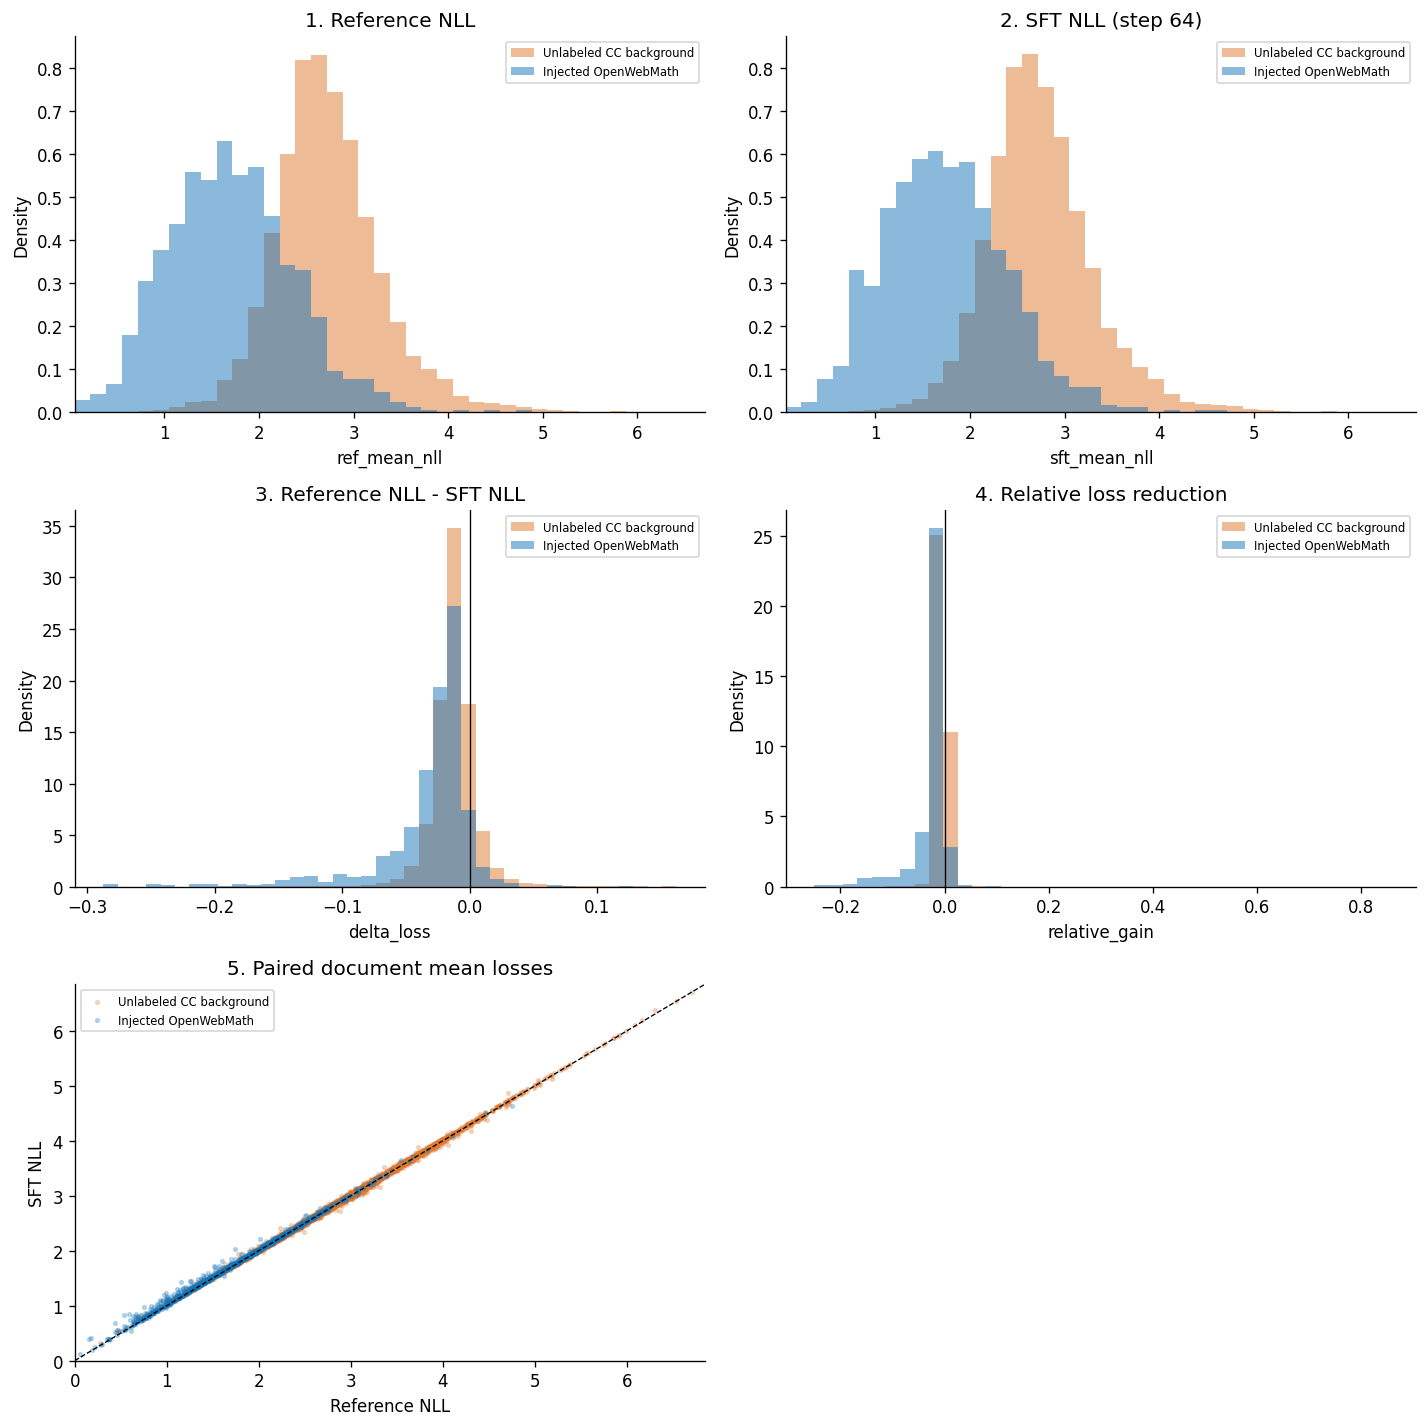

相对下降比例图显示 [-0.25, 0.85]；范围外样本仍参与所有统计： {'math': 9}


In [4]:
table=df.groupby('source').agg(documents=('id','size'),ref_NLL=('ref_mean_nll','mean'),sft_NLL=('sft_mean_nll','mean'),
                               mean_drop=('delta_loss','mean'),median_relative_drop=('relative_gain','median'),mean_tokens=('token_count','mean'))
table['fraction_improved']=df.groupby('source')['delta_loss'].apply(lambda x:(x>0).mean())
display(table.round(5))
fig=plt.figure(figsize=(12,12));grid=fig.add_gridspec(3,2)
axes=[fig.add_subplot(grid[i,j]) for i in range(2) for j in range(2)]+[fig.add_subplot(grid[2,0])]
nll_bins=np.histogram_bin_edges(df[['ref_mean_nll','sft_mean_nll']].to_numpy().ravel(),bins=40)
relative_range=(-.25,.85);relative_bins=np.linspace(*relative_range,41)
specs=[('ref_mean_nll','1. Reference NLL'),('sft_mean_nll','2. SFT NLL (step 64)'),
       ('delta_loss','3. Reference NLL - SFT NLL'),('relative_gain','4. Relative loss reduction')]
for ax,(key,title) in zip(axes,specs):
    bins=relative_bins if key=='relative_gain' else nll_bins if key.endswith('mean_nll') else np.histogram_bin_edges(df[key],bins=40)
    for source,g in df.groupby('source'):
        if key=='relative_gain':
            ax.hist(g[key],bins=bins,weights=np.full(len(g),1/(len(g)*(bins[1]-bins[0]))),alpha=.5,color=colors[source],label=names[source])
        else:ax.hist(g[key],bins=bins,density=True,alpha=.5,color=colors[source],label=names[source])
    ax.set(xlabel=key,ylabel='Density',title=title)
    if key in ['delta_loss','relative_gain']:ax.axvline(0,color='black',linewidth=.8)
ymax=max(ax.get_ylim()[1] for ax in axes[:2])
for ax in axes[:2]:ax.set(xlim=(nll_bins[0],nll_bins[-1]),ylim=(0,ymax))
for source,g in df.groupby('source'):axes[4].scatter(g.ref_mean_nll,g.sft_mean_nll,s=5,alpha=.25,color=colors[source],label=names[source])
bound=df[['ref_mean_nll','sft_mean_nll']].to_numpy().max()*1.02
axes[4].plot([0,bound],[0,bound],'k--',linewidth=.8)
axes[4].set(xlabel='Reference NLL',ylabel='SFT NLL',title='5. Paired document mean losses',xlim=(0,bound),ylim=(0,bound))
for ax in axes:ax.legend(fontsize=7)
fig.tight_layout();plt.show();plt.close(fig)
outside=df.loc[~df.relative_gain.between(*relative_range)]
print('相对下降比例图显示 [-0.25, 0.85]；范围外样本仍参与所有统计：',outside.groupby('source').size().to_dict())

### 3.1 Step 16 / 32 / 48 / 64 相对 step 0：八张分布图

以下是**事后追加的 checkpoint 诊断**，不改变原 step-64 正式结果、不选择 checkpoint，也不重新评分或训练。

- 四行依次为 step 16、32、48、64；左列为 loss 下降量，右列为相对下降比例，两项并列展示。
- 所有值都相对同一个 step-0 reference：`delta_loss = L0 - Lt`，`relative_gain = (L0 - Lt) / max(L0, 1e-6)`。**step 0 与自身比较恒为 0**，在每张图中以黑色虚线标出，不画虚假的有限密度分布。
- 每列在四个 step 间共用分箱和 x/y 坐标；每种来源各自按全部文档数归一化，文档等权。右列放大显示 `[-0.25, 0.15]`，范围外文档不丢弃、不重新归一化，数量在表格中单列，全部统计仍包含它们。
- 数据来自仓库中相邻的 `2026-10-23_165639Z_math-web-probe-diagnostics-qwen25-1p5b-seed42/snapshot/web_per_document.parquet`，运行时核验 SHA-256、文档集合、来源、评分 token 数、共享 reference，以及 step 64 与本页正式结果逐篇一致。这一追加部分需要该相邻诊断快照，但不需要挂载盘或 GPU。
- **直接复用项目已有虚拟环境**，不创建环境、不安装依赖。为避免当前 notebook 内核与项目环境不一致，新增单元通过项目 Python 子进程绘图，并把输出图保存到本 notebook。

绘图环境： /home/v-guanhechen/data-picking/.venv/bin/python
核对通过：4 个 checkpoint × 10,000 篇；reference 与正式 step-64 结果逐篇一致。
Step 0 两项变化恒为 0（黑色虚线）。右列显示 [-0.25, 0.15]，范围外文档仍参与全部统计。


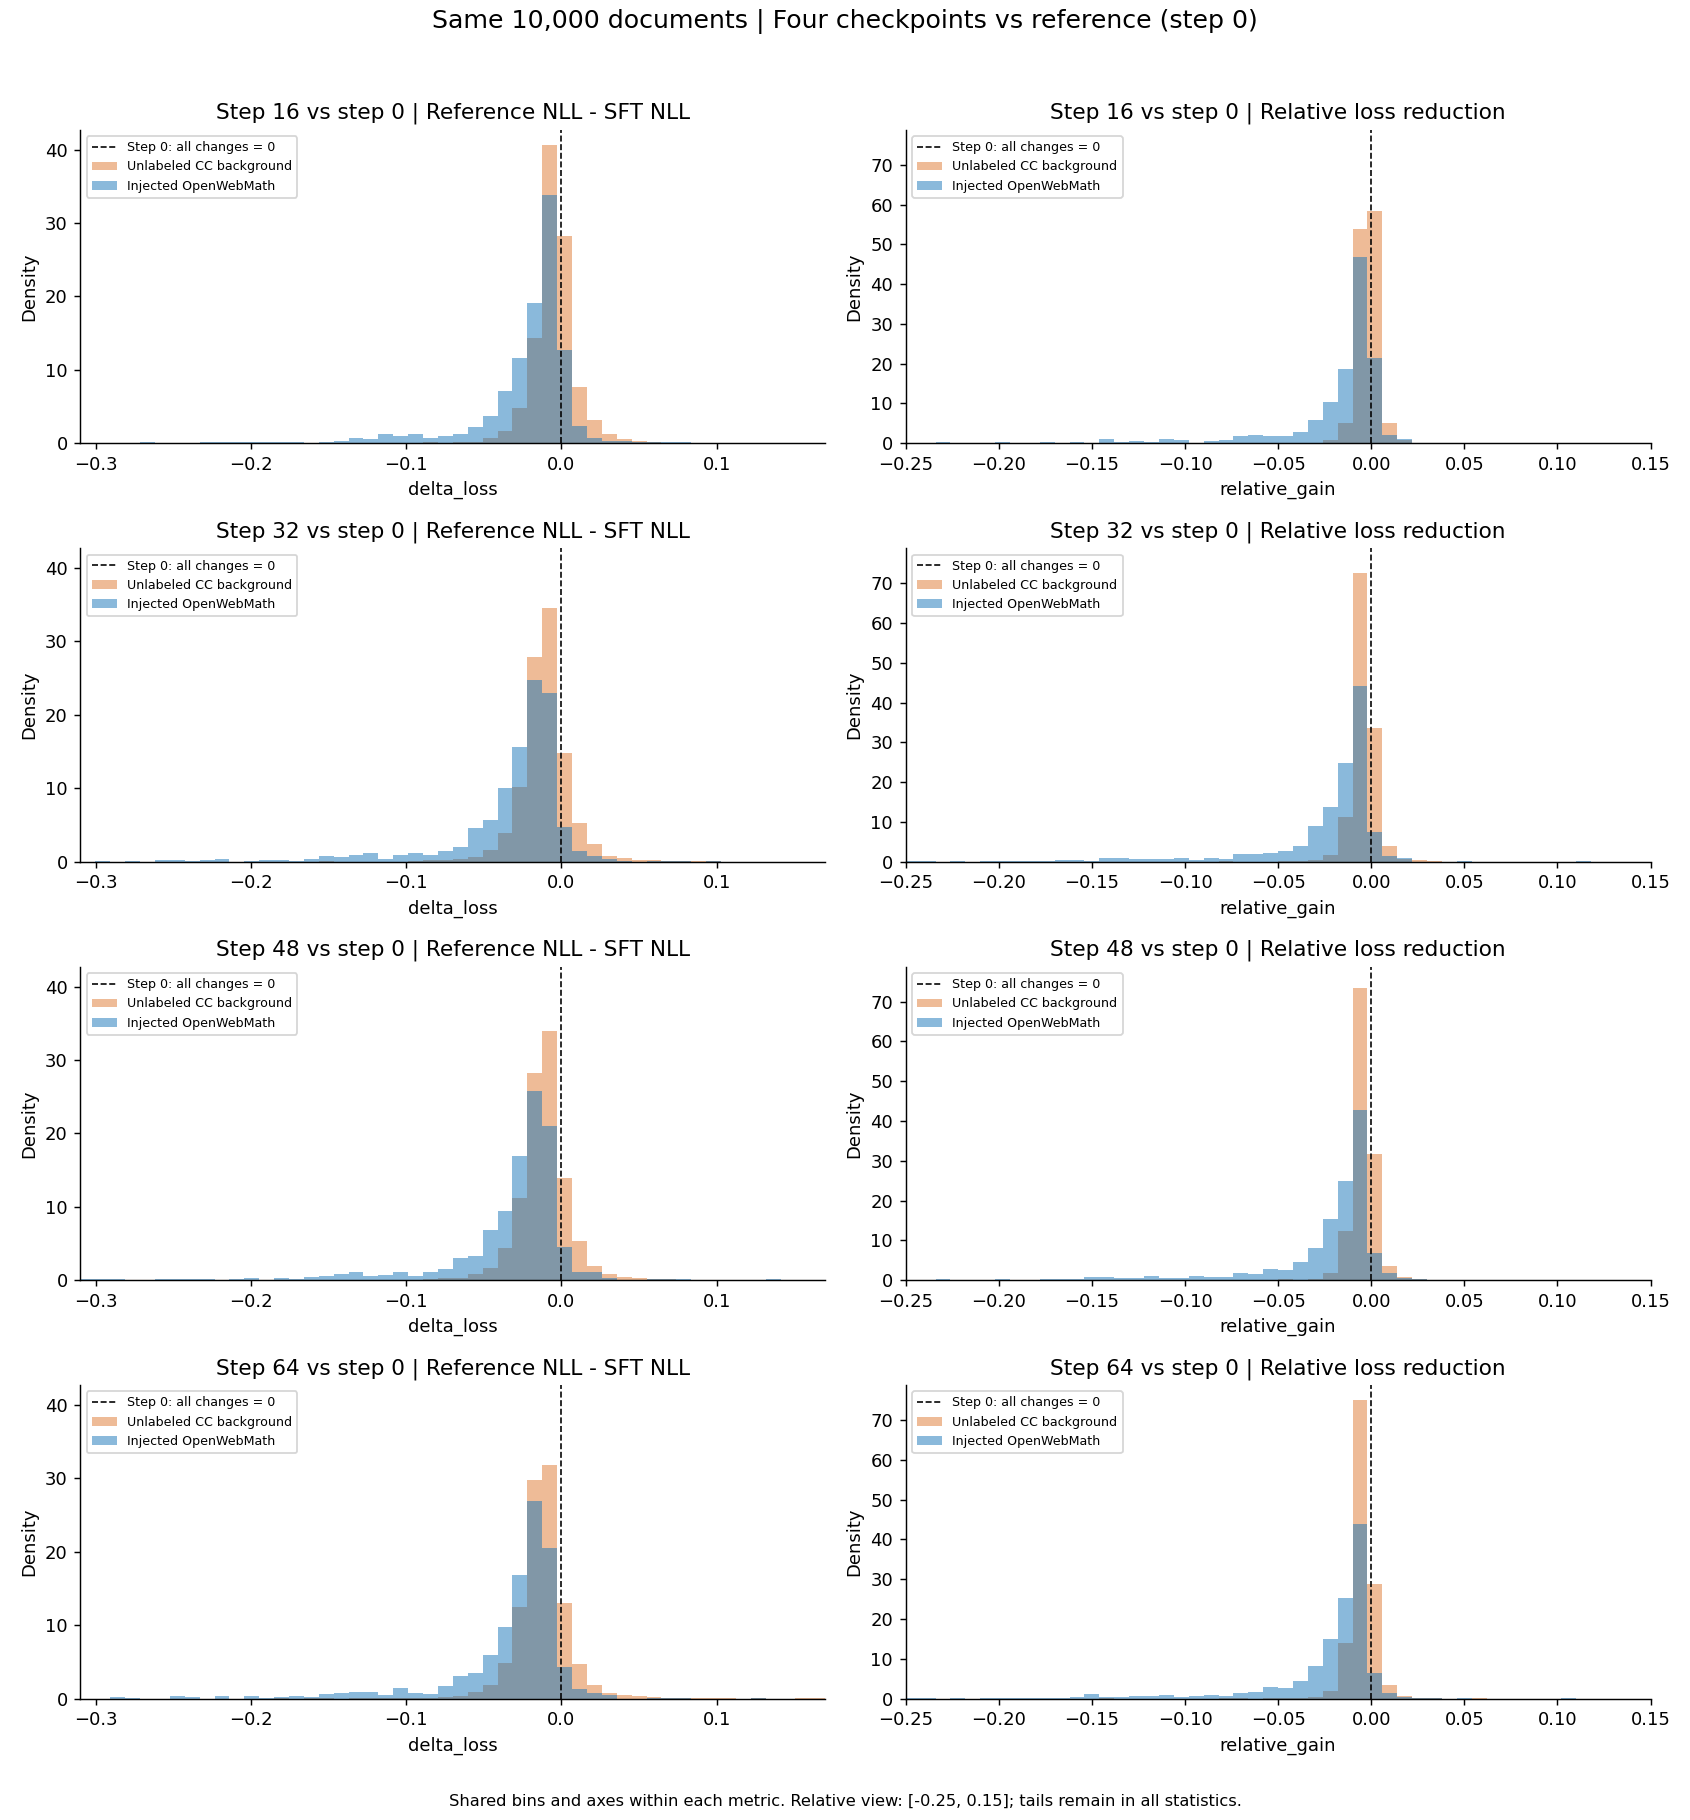

step,source,documents,mean_delta_loss,mean_relative_gain,fraction_improved,relative_outside_view
0,background,9000,0.000000,0.000000,0.000000,0
0,math,1000,0.000000,0.000000,0.000000,0
16,background,9000,-0.004677,-0.002011,0.286111,0
16,math,1000,-0.022861,-0.022069,0.099000,7
32,background,9000,-0.010546,-0.004198,0.175111,0
32,math,1000,-0.032167,-0.030226,0.059000,11
48,background,9000,-0.011171,-0.004433,0.168222,0
48,math,1000,-0.032552,-0.030857,0.060000,10
64,background,9000,-0.012174,-0.004794,0.155333,0
64,math,1000,-0.032328,-0.030362,0.056000,9


In [2]:
import base64 as _base64
import json as _json
from pathlib import Path as _Path
import subprocess as _subprocess
from IPython.display import Image as _Image, HTML as _HTML, display as _display

# 绘图脚本与本 notebook 放在同一实验目录，仍复用项目现有虚拟环境。
_directory = '2026-10-23_095832Z_math-web-probe-qwen25-1p5b-n4096-b64-s64-seed42'
_candidates = [_Path.cwd(), *_Path.cwd().parents, _Path('/home/v-guanhechen/data-picking')]
_analysis_candidates = [p for root in _candidates for p in (root, root / 'experiments-analysis' / _directory)]
_analysis = next((p for p in _analysis_candidates if p.name == _directory and (p / 'plot_web_checkpoints.py').is_file()), None)
if _analysis is None:
    raise FileNotFoundError('找不到当前实验目录中的 plot_web_checkpoints.py。')
_project = _analysis.parent.parent
_python = _project / '.venv/bin/python'
if not _python.is_file():
    raise FileNotFoundError(f'请使用已有项目环境：{_python}；本单元不会创建环境或安装包。')
_result = _subprocess.run(
    [str(_python), str(_analysis / 'plot_web_checkpoints.py')],
    cwd=_project, capture_output=True, text=True, timeout=180,
)
if _result.returncode:
    raise RuntimeError(_result.stderr or _result.stdout)
_checkpoint_plot = _json.loads(_result.stdout)
assert _checkpoint_plot['validated_steps'] == [16, 32, 48, 64] and _checkpoint_plot['panels'] == 8
print('绘图环境：', _python)
print('核对通过：4 个 checkpoint × 10,000 篇；reference 与正式 step-64 结果逐篇一致。')
print('Step 0 两项变化恒为 0（黑色虚线）。右列显示 [-0.25, 0.15]，范围外文档仍参与全部统计。')
_display(_Image(data=_base64.b64decode(_checkpoint_plot['image_png_base64'])))
_display(_HTML(_checkpoint_plot['summary_html']))

## 4. 能否找回注入的数学相关文档？

,指标,AUC,AUC 95% CI,AP
0,loss 下降量,0.3046,"[0.2856, 0.3226]",0.0677
1,相对下降比例,0.2137,"[0.1962, 0.2312]",0.0635
2,ref loss，低值优先,0.8872,"[0.8745, 0.8999]",0.6402
3,SFT loss，低值优先,0.8850,"[0.8723, 0.8978]",0.6336


,指标,选取比例,文档数,找回注入文档,来源 precision,注入集 recall,recall 95% CI,相对随机富集倍数
0,loss 下降量,1%,100,4,0.040,0.004,"[0.0010, 0.0090]",0.40
1,loss 下降量,5%,500,21,0.042,0.021,"[0.0120, 0.0300]",0.42
2,loss 下降量,10%,1000,39,0.039,0.039,"[0.0270, 0.0510]",0.39
3,相对下降比例,1%,100,9,0.090,0.009,"[0.0040, 0.0150]",0.90
4,相对下降比例,5%,500,28,0.056,0.028,"[0.0180, 0.0380]",0.56
5,相对下降比例,10%,1000,45,0.045,0.045,"[0.0340, 0.0600]",0.45
6,ref loss，低值优先,1%,100,96,0.960,0.096,"[0.0910, 0.0990]",9.60
7,ref loss，低值优先,5%,500,399,0.798,0.399,"[0.3830, 0.4170]",7.98
8,ref loss，低值优先,10%,1000,610,0.610,0.610,"[0.5860, 0.6340]",6.10
9,SFT loss，低值优先,1%,100,94,0.940,0.094,"[0.0900, 0.0990]",9.40


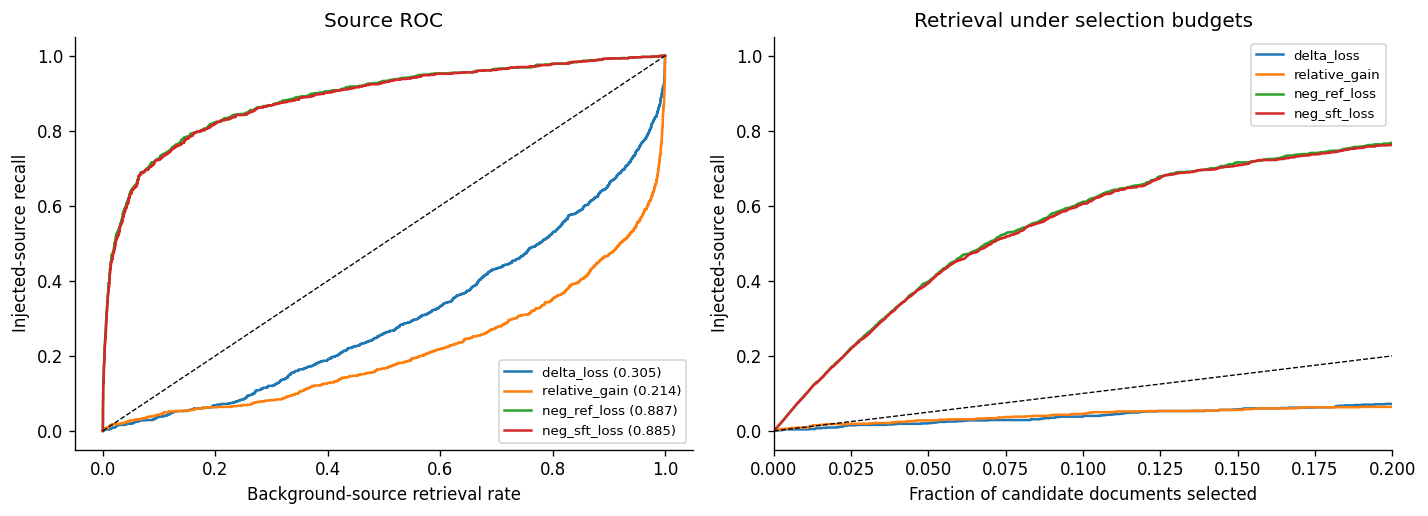

原始池随机 precision 期望为 10%；这里的 precision 衡量注入来源，不能当作真实数学内容纯度。


In [5]:
for frame,result in [(df,metrics['main']),(matched,metrics['length_matched'])]:
    y=frame.injected_math_source.to_numpy(dtype=int)
    ties=np.random.default_rng(result['tie_seed']).random(len(frame))
    for key,value in result['scores'].items():
        np.testing.assert_allclose(roc_auc_score(y,frame[key]),value['roc_auc'],rtol=0,atol=1e-12)
        np.testing.assert_allclose(average_precision_score(y,frame[key]),value['average_precision'],rtol=0,atol=1e-12)
        order=np.lexsort((ties,-frame[key].to_numpy()))
        for f,top in value['top'].items():assert int(y[order[:top['k']]].sum())==top['retrieved_math_source']
def metric_table(result,columns=keys):
    return pd.DataFrame([{'指标':labels.get(k,k),'AUC':round(result['scores'][k]['roc_auc'],4),
        'AUC 95% CI':interval(result['scores'][k]['roc_auc_ci95']),'AP':round(result['scores'][k]['average_precision'],4)} for k in columns])
display(metric_table(metrics['main']))
rows=[]
for key in keys:
    for f,v in metrics['main']['scores'][key]['top'].items():
        rows.append({'指标':labels[key],'选取比例':f'{float(f):.0%}','文档数':v['k'],'找回注入文档':v['retrieved_math_source'],
                     '来源 precision':v['source_precision'],'注入集 recall':v['source_recall'],
                     'recall 95% CI':interval(v['source_recall_ci95']),'相对随机富集倍数':v['source_enrichment']})
display(pd.DataFrame(rows).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
y=df.injected_math_source.to_numpy(dtype=int)
ties=np.random.default_rng(metrics['main']['tie_seed']).random(len(df))
for key in keys:
    fpr,tpr,_=roc_curve(y,df[key]);axes[0].plot(fpr,tpr,label=f'{key} ({roc_auc_score(y,df[key]):.3f})')
    order=np.lexsort((ties,-df[key].to_numpy()))
    axes[1].plot(np.arange(1,len(df)+1)/len(df),np.cumsum(y[order])/y.sum(),label=key)
for ax in axes:ax.plot([0,1],[0,1],'k--',linewidth=.8);ax.legend(fontsize=8)
axes[0].set(xlabel='Background-source retrieval rate',ylabel='Injected-source recall',title='Source ROC')
axes[1].set(xlabel='Fraction of candidate documents selected',ylabel='Injected-source recall',xlim=(0,.2),title='Retrieval under selection budgets')
fig.tight_layout();plt.show();plt.close(fig)
print('原始池随机 precision 期望为 10%；这里的 precision 衡量注入来源，不能当作真实数学内容纯度。')

## 5. 长度控制与相对原始 loss 基线的差异

长度匹配： {'quantile_edges': [225.0, 466.0, 925.0], 'background_per_math': 9, 'bins': [{'bin': 0, 'math': 151, 'background': 2336, 'retained_math': 151, 'retained_background': 1359}, {'bin': 1, 'math': 182, 'background': 2329, 'retained_math': 182, 'retained_background': 1638}, {'bin': 2, 'math': 173, 'background': 2328, 'retained_math': 173, 'retained_background': 1557}, {'bin': 3, 'math': 494, 'background': 2007, 'retained_math': 223, 'retained_background': 2007}], 'retained_documents': 7290, 'retained_math': 729, 'retained_fraction': 0.729}


,指标,AUC,AUC 95% CI,AP
0,loss 下降量,0.2924,"[0.2700, 0.3142]",0.0698
1,相对下降比例,0.2123,"[0.1918, 0.2343]",0.0683
2,ref loss，低值优先,0.8796,"[0.8639, 0.8951]",0.6435
3,SFT loss，低值优先,0.8768,"[0.8607, 0.8926]",0.6346


,pool,positive,negative
0,raw,0.663432,0.336568
1,matched,0.520659,0.479341


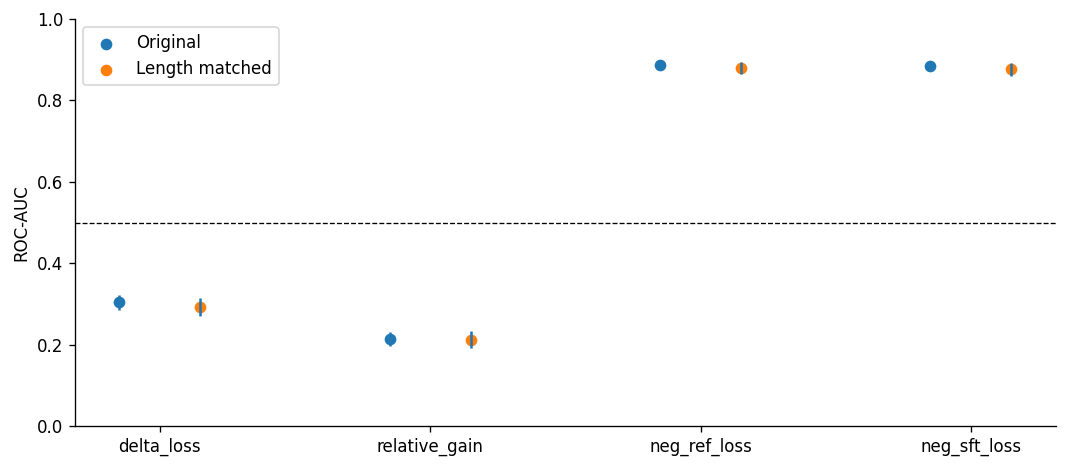

,pool,比较,AUC 差,配对 95% CI
0,raw,delta_loss − neg_ref_loss,-0.5826,"[-0.6061, -0.5597]"
1,raw,delta_loss − neg_sft_loss,-0.5804,"[-0.6040, -0.5576]"
2,raw,relative_gain − neg_ref_loss,-0.6735,"[-0.6977, -0.6485]"
3,raw,relative_gain − neg_sft_loss,-0.6713,"[-0.6952, -0.6465]"
4,matched,delta_loss − neg_ref_loss,-0.5872,"[-0.6151, -0.5582]"
5,matched,delta_loss − neg_sft_loss,-0.5844,"[-0.6121, -0.5554]"
6,matched,relative_gain − neg_ref_loss,-0.6673,"[-0.6959, -0.6374]"
7,matched,relative_gain − neg_sft_loss,-0.6645,"[-0.6930, -0.6347]"


In [6]:
print('长度匹配：',metrics['length_matching'])
display(metric_table(metrics['length_matched']))
display(pd.DataFrame([{'pool':name,**m['length_baselines']} for name,m in [('raw',metrics['main']),('matched',metrics['length_matched'])]]))
fig,ax=plt.subplots(figsize=(9,4))
for shift,name,result in [(-.15,'Original',metrics['main']),(.15,'Length matched',metrics['length_matched'])]:
    x=np.arange(len(keys))+shift;ax.scatter(x,[result['scores'][k]['roc_auc'] for k in keys],label=name)
    for xi,k in zip(x,keys):ax.vlines(xi,*result['scores'][k]['roc_auc_ci95'])
ax.axhline(.5,color='black',linestyle='--',linewidth=.8)
ax.set(xticks=np.arange(len(keys)),xticklabels=keys,ylabel='ROC-AUC',ylim=(0,1));ax.legend()
fig.tight_layout();plt.show();plt.close(fig)
records=[]
for pool,result in [('raw',metrics['main']),('matched',metrics['length_matched'])]:
    for key in ['delta_loss','relative_gain']:
        for base in ['neg_ref_loss','neg_sft_loss']:
            v=result['paired_auc_differences'][key][base]
            records.append({'pool':pool,'比较':key+' − '+base,'AUC 差':v['difference'],'配对 95% CI':interval(v['ci95'])})
display(pd.DataFrame(records).round(4))

长度匹配按混合池的 token 数四分位分桶，桶内随机抽取并维持 1:9 来源比例。它改变了评估人群，不能保证消除桶内长度、网站风格或上游清洗差异。

## 6. 观察与局限

In [7]:
lines=[]
for key in ['delta_loss','relative_gain']:
    raw=metrics['main']['scores'][key];control=metrics['length_matched']['scores'][key]
    v=raw['top']['0.1']
    lines.append(f"{labels[key]}：原始 AUC {raw['roc_auc']:.4f}（{interval(raw['roc_auc_ci95'])}），"
                 f"长度匹配 AUC {control['roc_auc']:.4f}；前 {v['k']} 篇找回 {v['retrieved_math_source']} 篇注入文档（recall {v['source_recall']:.1%}）。")
    lo,hi=raw['roc_auc_ci95']
    if hi<.5:
        lines.append(f"{labels[key]}在预设方向上的 AUC 低于 0.5：较高分数更偏向背景来源，没有事后翻转分数。")
    elif lo>.5:
        lines.append(f"{labels[key]}在预设方向上有注入来源的区分信号；仍需结合原始 loss 基线判断额外信息。")
    else:
        lines.append(f"{labels[key]}的区间覆盖 0.5，本轮尚无稳定的正向区分证据。")
for source,g in metrics['document_summary'].items():
    lines.append(f"{names[source]}：平均文档 NLL {g['ref_mean_nll']['mean']:.4f} → {g['sft_mean_nll']['mean']:.4f}。")
display(Markdown('\n\n'.join(lines)))
print('相对下降分母保护触发数：',metrics['relative_gain_denominator_clamps'])
display(metric_table(metrics['main'],columns=['pos_ref_loss','pos_sft_loss']))

loss 下降量：原始 AUC 0.3046（[0.2856, 0.3226]），长度匹配 AUC 0.2924；前 1000 篇找回 39 篇注入文档（recall 3.9%）。

loss 下降量在预设方向上的 AUC 低于 0.5：较高分数更偏向背景来源，没有事后翻转分数。

相对下降比例：原始 AUC 0.2137（[0.1962, 0.2312]），长度匹配 AUC 0.2123；前 1000 篇找回 45 篇注入文档（recall 4.5%）。

相对下降比例在预设方向上的 AUC 低于 0.5：较高分数更偏向背景来源，没有事后翻转分数。

Unlabeled CC background：平均文档 NLL 2.7339 → 2.7460。

Injected OpenWebMath：平均文档 NLL 1.7053 → 1.7377。

相对下降分母保护触发数： 0


,指标,AUC,AUC 95% CI,AP
0,pos_ref_loss,0.1128,"[0.1001, 0.1255]",0.0541
1,pos_sft_loss,0.1150,"[0.1022, 0.1277]",0.0542


这是指定分片、指定抓取批次、一个训练 seed 上的来源检索结果。Bootstrap 不包含训练随机性，
也没有完整覆盖同站点文风的相关性。上游提取差异、网页主题与来源标记之间的混杂仍需后续检验。
尚未人工标注背景网页的数学相关性，未训练通用 SFT 对照，也未做等 token 预算的选数后训练对照。
因此本轮不能直接证明选中的文档带来更大的数学训练收益。

## 附录：固定随机子集的整篇文档梯度

documents  tokens_median  norm_median  max_abs_median  \
model     source                                                              
reference background         64          437.0     13.99146         1.45472   
          math               64         1210.5      7.01062         0.71365   
sft       background         64          437.0     13.37016         1.51681   
          math               64         1210.5      6.51934         0.85759   

                      cos_to_A1_median  
model     source                        
reference background           0.00765  
          math                 0.01089  
sft       background           0.00043  
          math                 0.00635

,reference,sft
norm,7.590022,1.092538
mean_nll,0.722413,0.469912
parameter_count,1543714304,1543714304


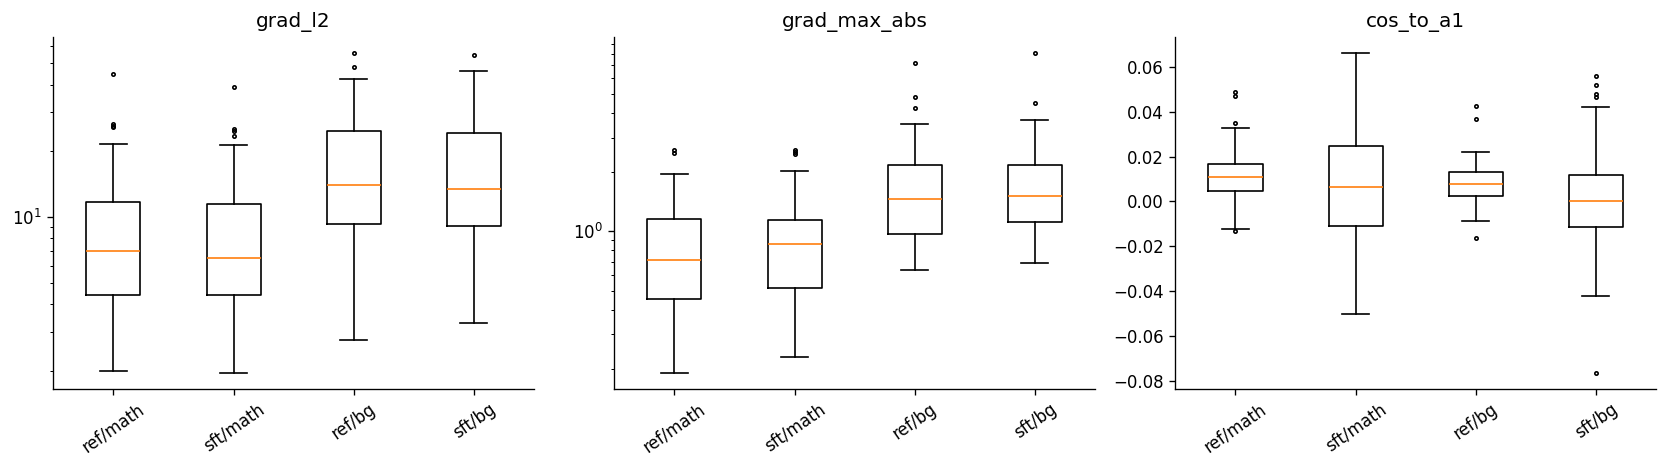

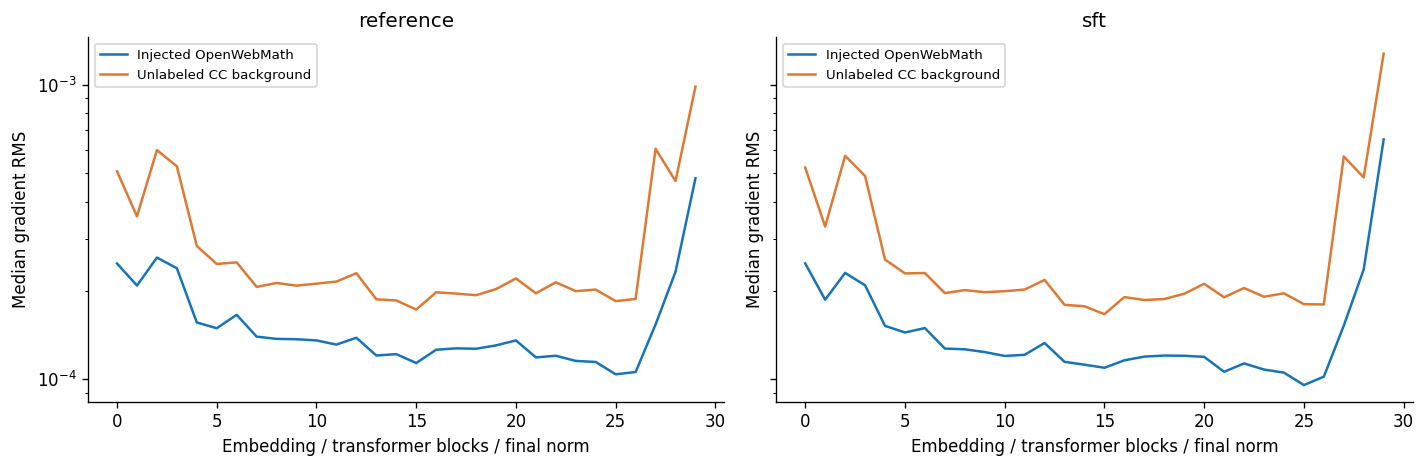

文档梯度与完整评分的 NLL 最大差： {'reference': 3.432008786052876e-06, 'sft': 2.230520660173596e-06}


In [8]:
gradient=load('gradient_summary.json')
g=pd.read_parquet(SNAP/'gradient_per_example.parquet')
layers=pd.read_parquet(SNAP/'gradient_per_layer.parquet')
assert g.groupby(['model','source']).size().to_dict()=={('reference','background'):64,('reference','math'):64,('sft','background'):64,('sft','math'):64}
display(g.groupby(['model','source']).agg(documents=('id','size'),tokens_median=('token_count','median'),
    norm_median=('grad_l2','median'),max_abs_median=('grad_max_abs','median'),cos_to_A1_median=('cos_to_a1','median')).round(5))
display(pd.DataFrame(gradient['anchors']).loc[['norm','mean_nll','parameter_count']])
fig,axes=plt.subplots(1,3,figsize=(14,4))
order=[('reference','math'),('sft','math'),('reference','background'),('sft','background')]
for ax,key in zip(axes,['grad_l2','grad_max_abs','cos_to_a1']):
    values=[g.loc[(g.model==m)&(g.source==s),key] for m,s in order]
    ax.boxplot(values,tick_labels=['ref/math','sft/math','ref/bg','sft/bg'],flierprops={'markersize':2})
    ax.set(title=key);ax.tick_params(axis='x',rotation=35)
    if key!='cos_to_a1':ax.set_yscale('log')
fig.tight_layout();plt.show();plt.close(fig)
layer_order=['embedding']+sorted(k for k in layers.layer.unique() if k.startswith('layer_'))
layer_order+=sorted(k for k in layers.layer.unique() if k not in layer_order)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,model in zip(axes,['reference','sft']):
    for source in ['math','background']:
        values=layers.loc[(layers.model==model)&(layers.source==source)].groupby('layer').grad_rms.median().reindex(layer_order)
        ax.plot(range(len(values)),values,label=names[source],color=colors[source])
    ax.set(yscale='log',title=model,xlabel='Embedding / transformer blocks / final norm',ylabel='Median gradient RMS');ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
print('文档梯度与完整评分的 NLL 最大差：',gradient['max_nll_crosscheck_error'])

梯度样本在查看检索结果前按 seed 固定，每来源 64 篇，全部窗口参与计算。
`g(d)` 是整篇 token 加权平均 NLL 的梯度，先累积各窗口梯度再计算 norm；不是窗口 norm 的平均。
完整 FP32、eval、SDPA math，不裁剪、不执行 optimizer update，绑定参数只计一次。
两模型分别用同一批 128 条 A1 构造各自平均梯度，cosine 参照会随模型改变。
这里的子集诊断不替代 10,000 篇候选池的检索统计；原始逐参数明细保存在运行目录。